In [46]:
import pandas as pd
import numpy as np

# File paths
files = [
    ("distanceRecordingDataXAXIS.xlsx", "XAXIS"),
    ("distanceRecordingDataXAXIS_z3.xlsx", "XAXIS_z3"),
    ("distanceRecordingDataXAXIS_z5.xlsx", "XAXIS_z5"),
]

XAxis = []

for file_name, label in files:
    # Read the Excel sheet
    df = pd.read_excel(file_name, sheet_name="raw_log")

    # Group by distance and calculate stats for Bx_uT
    stats = (
        df.groupby("distance_mm")["Bx_uT"]
        .agg(["mean", "min", "max"])
        .reset_index()
    )

    # # Rename columns to make them clearer
    # stats.rename(columns={
    #     "mean": "Bx_mean_uT",
    #     "min": "Bx_min_uT",
    #     "max": "n"
    # }, inplace=True)

    # Standard error
    stats["HighErr"] = stats["max"] - stats["mean"]
    stats["LowErr"] = stats["mean"] - stats["min"]

    # Add dataset label
    stats["dataset"] = label

    XAxis.append(stats)

# Combine all three datasets
final_df = pd.concat(XAxis, ignore_index=True)

# Reorder columns
final_df = final_df[
    ["dataset", "distance_mm", "mean", "min", "max", 'HighErr', "LowErr"]
].sort_values(["distance_mm", "dataset"])

# Print result
print(final_df)

# Optional: save to a new Excel file
# final_df.to_excel("Bx_distance_summary.xlsx", index=False)

     dataset  distance_mm      mean    min    max    HighErr     LowErr
0      XAXIS            0  0.000722  -0.10   0.08   0.079278   0.100722
9   XAXIS_z3            0 -0.845140  -1.63   0.56   1.405140   0.784860
18  XAXIS_z5            0 -1.144317  -1.73  -0.56   0.584317   0.585683
1      XAXIS            1  0.000110  -1.26   0.22   0.219890   1.260110
10  XAXIS_z3            1  0.061557  -1.32   5.88   5.818443   1.381557
19  XAXIS_z5            1 -0.472805 -12.30   0.21   0.682805  11.827195
2      XAXIS            2 -0.003135  -0.08   0.07   0.073135   0.076865
11  XAXIS_z3            2  0.116257  -2.13  32.77  32.653743   2.246257
20  XAXIS_z5            2 -0.008800  -0.72   0.20   0.208800   0.711200
3      XAXIS            3 -0.001535  -2.00   0.07   0.071535   1.998465
12  XAXIS_z3            3  0.022464  -0.04   0.34   0.317536   0.062464
21  XAXIS_z5            3  0.103710  -0.05   0.41   0.306290   0.153710
4      XAXIS            4 -0.001391  -0.05   0.05   0.051391   0

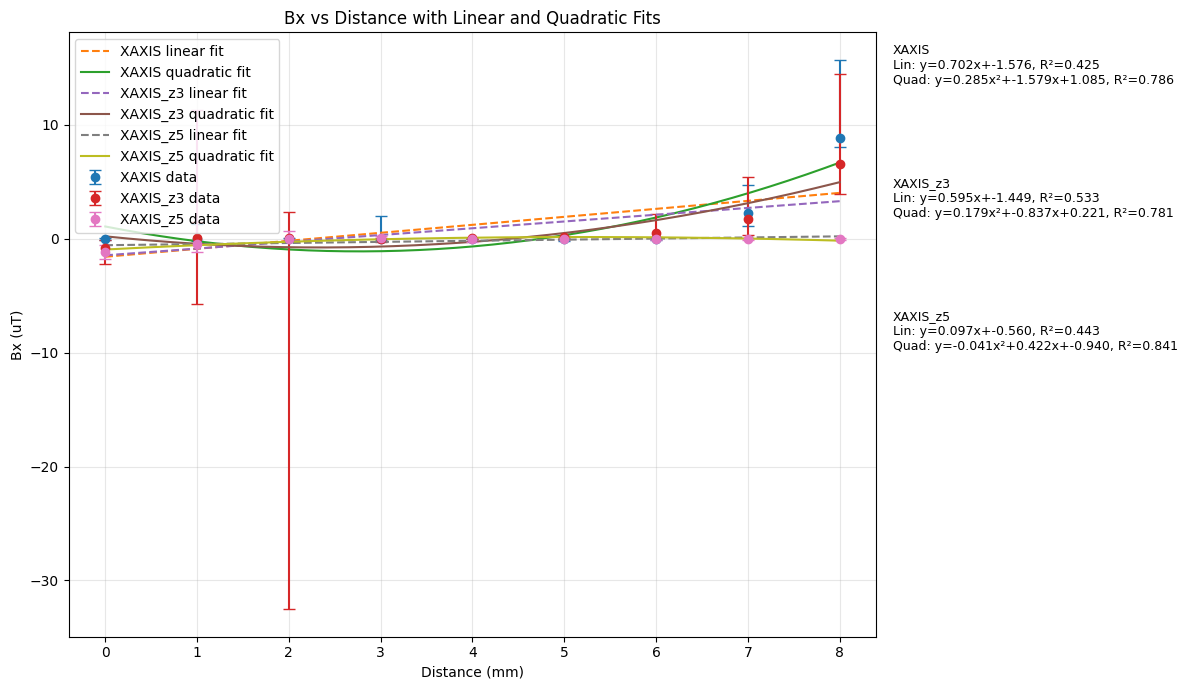

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

text_y = 0.98  # starting y position for text
ax = plt.gca()

for dataset in final_df["dataset"].unique():
    subset = final_df[final_df["dataset"] == dataset].sort_values("distance_mm")

    x = subset["distance_mm"].to_numpy()
    y = subset["mean"].to_numpy()
    yerr = [subset["HighErr"].to_numpy(), subset["LowErr"].to_numpy()]

    plt.errorbar(
        x, y, yerr=yerr,
        marker='o',
        linestyle='',
        capsize=4,
        label=f"{dataset} data"
    )

    x_fit = np.linspace(x.min(), x.max(), 200)


    # Linear fit
    coeffs_linear = np.polyfit(x, y, 1)
    y_linear_fit = np.polyval(coeffs_linear, x_fit)
    y_linear_pred = np.polyval(coeffs_linear, x)

    # Quadratic fit
    coeffs_quad = np.polyfit(x, y, 2)
    y_quad_fit = np.polyval(coeffs_quad, x_fit)
    y_quad_pred = np.polyval(coeffs_quad, x)

    # R^2 for linear
    ss_res_lin = np.sum((y - y_linear_pred) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    r2_lin = 1 - (ss_res_lin / ss_tot)

    # R^2 for quadratic
    ss_res_quad = np.sum((y - y_quad_pred) ** 2)
    r2_quad = 1 - (ss_res_quad / ss_tot)

    plt.plot(x_fit, y_linear_fit, linestyle='--', label=f"{dataset} linear fit")
    plt.plot(x_fit, y_quad_fit, linestyle='-', label=f"{dataset} quadratic fit")

    m, b = coeffs_linear
    a, b2, c = coeffs_quad

    eq_text = (
        f"{dataset}\n"
        f"Lin: y={m:.3f}x+{b:.3f}, R²={r2_lin:.3f}\n"
        f"Quad: y={a:.3f}x²+{b2:.3f}x+{c:.3f}, R²={r2_quad:.3f}"
    )

    ax.text(
        1.02, text_y, eq_text,
        transform=ax.transAxes,
        fontsize=9,
        verticalalignment='top'
    )
    text_y -= 0.22

plt.xlabel("Distance (mm)")
plt.ylabel("Bx (uT)")
plt.title("Bx vs Distance with Linear and Quadratic Fits")
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [48]:
YAxis = []

for file_name, label in files:
    # Read the Excel sheet
    df = pd.read_excel(file_name, sheet_name="raw_log")

    # Group by distance and calculate stats for Bx_uT
    stats = (
        df.groupby("distance_mm")["By_uT"]
        .agg(["mean", "min", "max"])
        .reset_index()
    )

    # # Rename columns to make them clearer
    # stats.rename(columns={
    #     "mean": "Bx_mean_uT",
    #     "min": "Bx_min_uT",
    #     "max": "n"
    # }, inplace=True)

    # Standard error
    stats["HighErr"] = stats["max"] - stats["mean"]
    stats["LowErr"] = stats["mean"] - stats["min"]

    # Add dataset label
    stats["dataset"] = label

    YAxis.append(stats)

# Combine all three datasets
final_df_y = pd.concat(YAxis, ignore_index=True)

# Reorder columns
final_df_y = final_df_y[
    ["dataset", "distance_mm", "mean", "min", "max", 'HighErr', "LowErr"]
].sort_values(["distance_mm", "dataset"])

# Print result
print(final_df_y)

     dataset  distance_mm      mean    min    max    HighErr     LowErr
0      XAXIS            0  0.001947  -0.09   0.09   0.088053   0.091947
9   XAXIS_z3            0 -0.173674  -1.73   1.84   2.013674   1.556326
18  XAXIS_z5            0 -0.001229  -0.08   0.05   0.051229   0.078771
1      XAXIS            1 -0.025408 -12.59   0.19   0.215408  12.564592
10  XAXIS_z3            1 -0.006384  -1.96   0.22   0.226384   1.953616
19  XAXIS_z5            1  0.002959  -0.05   0.56   0.557041   0.052959
2      XAXIS            2  0.000594  -0.06   0.06   0.059406   0.060594
11  XAXIS_z3            2  0.051959  -1.34  19.40  19.348041   1.391959
20  XAXIS_z5            2  0.003895  -0.08   0.08   0.076105   0.083895
3      XAXIS            3 -0.000020  -0.70   0.33   0.330020   0.699980
12  XAXIS_z3            3  0.001828  -0.06   0.08   0.078172   0.061828
21  XAXIS_z5            3  0.001391  -0.10   0.07   0.068609   0.101391
4      XAXIS            4  0.000766  -0.06   0.05   0.049234   0

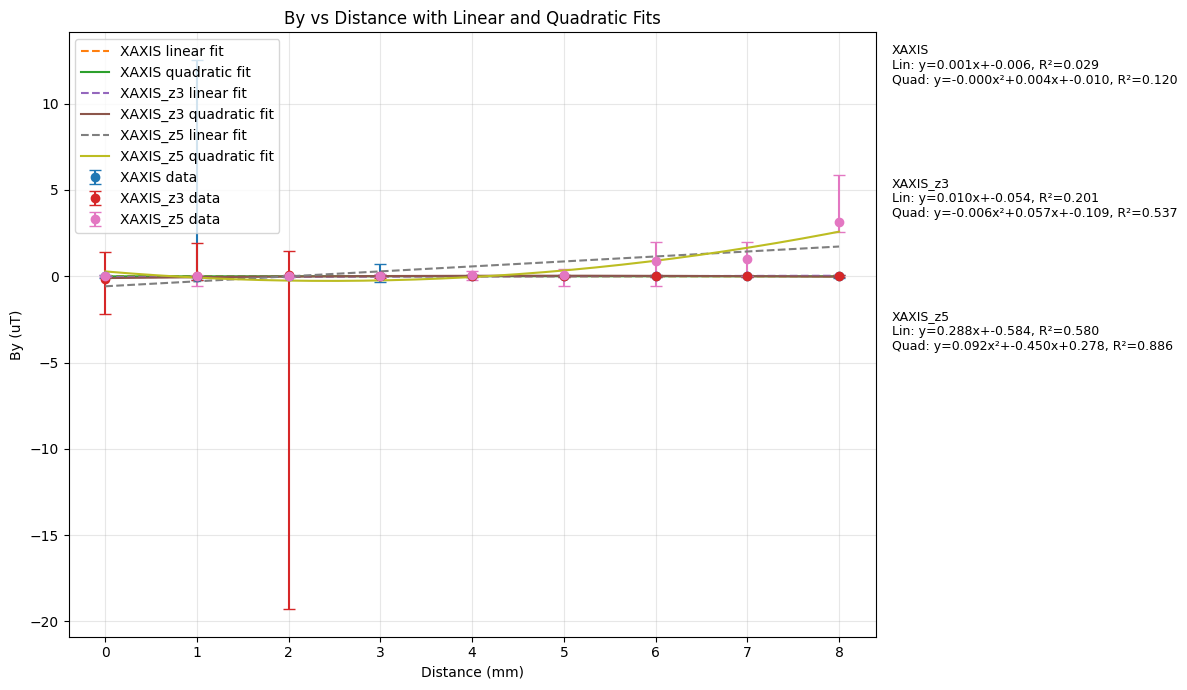

In [49]:
plt.figure(figsize=(12, 7))

text_y = 0.98  # starting y position for text
ax = plt.gca()

for dataset in final_df_y["dataset"].unique():
    subset = final_df_y[final_df_y["dataset"] == dataset].sort_values("distance_mm")

    x = subset["distance_mm"].to_numpy()
    y = subset["mean"].to_numpy()
    yerr = [subset["HighErr"].to_numpy(), subset["LowErr"].to_numpy()]

    plt.errorbar(
        x, y, yerr=yerr,
        marker='o',
        linestyle='',
        capsize=4,
        label=f"{dataset} data"
    )

    x_fit = np.linspace(x.min(), x.max(), 200)


    # Linear fit
    coeffs_linear = np.polyfit(x, y, 1)
    y_linear_fit = np.polyval(coeffs_linear, x_fit)
    y_linear_pred = np.polyval(coeffs_linear, x)

    # Quadratic fit
    coeffs_quad = np.polyfit(x, y, 2)
    y_quad_fit = np.polyval(coeffs_quad, x_fit)
    y_quad_pred = np.polyval(coeffs_quad, x)

    # R^2 for linear
    ss_res_lin = np.sum((y - y_linear_pred) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    r2_lin = 1 - (ss_res_lin / ss_tot)

    # R^2 for quadratic
    ss_res_quad = np.sum((y - y_quad_pred) ** 2)
    r2_quad = 1 - (ss_res_quad / ss_tot)

    plt.plot(x_fit, y_linear_fit, linestyle='--', label=f"{dataset} linear fit")
    plt.plot(x_fit, y_quad_fit, linestyle='-', label=f"{dataset} quadratic fit")

    m, b = coeffs_linear
    a, b2, c = coeffs_quad

    eq_text = (
        f"{dataset}\n"
        f"Lin: y={m:.3f}x+{b:.3f}, R²={r2_lin:.3f}\n"
        f"Quad: y={a:.3f}x²+{b2:.3f}x+{c:.3f}, R²={r2_quad:.3f}"
    )

    ax.text(
        1.02, text_y, eq_text,
        transform=ax.transAxes,
        fontsize=9,
        verticalalignment='top'
    )
    text_y -= 0.22

plt.xlabel("Distance (mm)")
plt.ylabel("By (uT)")
plt.title("By vs Distance with Linear and Quadratic Fits")
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [50]:
ZAxis = []

for file_name, label in files:
    # Read the Excel sheet
    df = pd.read_excel(file_name, sheet_name="raw_log")

    # Group by distance and calculate stats for Bx_uT
    stats = (
        df.groupby("distance_mm")["Bz_uT"]
        .agg(["mean", "min", "max"])
        .reset_index()
    )

    # # Rename columns to make them clearer
    # stats.rename(columns={
    #     "mean": "Bx_mean_uT",
    #     "min": "Bx_min_uT",
    #     "max": "n"
    # }, inplace=True)

    # Standard error
    stats["HighErr"] = stats["max"] - stats["mean"]
    stats["LowErr"] = stats["mean"] - stats["min"]

    # Add dataset label
    stats["dataset"] = label

    ZAxis.append(stats)

# Combine all three datasets
final_df_z = pd.concat(ZAxis, ignore_index=True)

# Reorder columns
final_df_z = final_df_z[
    ["dataset", "distance_mm", "mean", "min", "max", 'HighErr', "LowErr"]
].sort_values(["distance_mm", "dataset"])

# Print result
print(final_df_z)

     dataset  distance_mm       mean   min    max   HighErr     LowErr
0      XAXIS            0   0.000377 -0.06   0.06  0.059623   0.060377
9   XAXIS_z3            0   0.080593  0.01   0.17  0.089407   0.070593
18  XAXIS_z5            0  -0.001416 -0.06   0.05  0.051416   0.058584
1      XAXIS            1   0.002627 -0.06   0.87  0.867373   0.062627
10  XAXIS_z3            1   0.000126 -0.06   0.47  0.469874   0.060126
19  XAXIS_z5            1  -0.082553 -0.17   0.02  0.102553   0.087447
2      XAXIS            2   0.002275 -0.06   0.09  0.087725   0.062275
11  XAXIS_z3            2   0.004591 -0.05   0.43  0.425409   0.054591
20  XAXIS_z5            2  -0.233326 -0.35  -0.01  0.223326   0.116674
3      XAXIS            3   0.009778 -0.43   5.05  5.040222   0.439778
12  XAXIS_z3            3   0.001458 -0.06   0.20  0.198542   0.061458
21  XAXIS_z5            3   0.298266 -0.29   0.94  0.641734   0.588266
4      XAXIS            4   0.001512 -0.05   0.06  0.058488   0.051512
13  XA

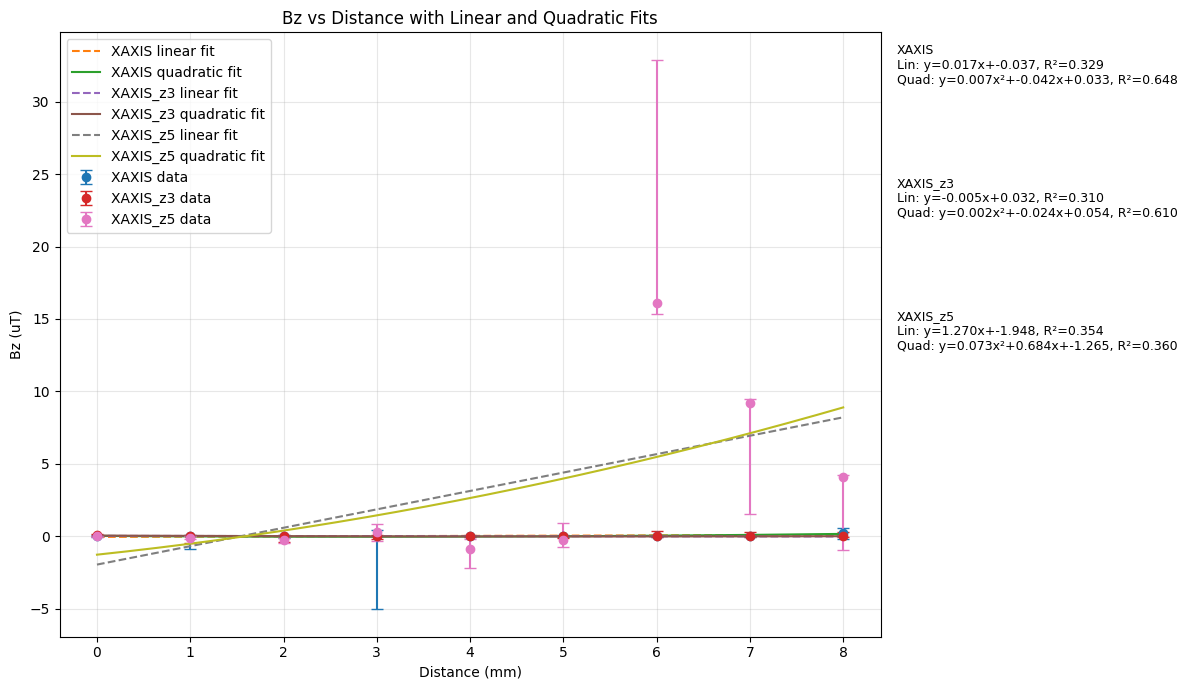

In [51]:
plt.figure(figsize=(12, 7))

text_y = 0.98  # starting y position for text
ax = plt.gca()

for dataset in final_df_z["dataset"].unique():
    subset = final_df_z[final_df_z["dataset"] == dataset].sort_values("distance_mm")

    x = subset["distance_mm"].to_numpy()
    y = subset["mean"].to_numpy()
    yerr = [subset["HighErr"].to_numpy(), subset["LowErr"].to_numpy()]

    plt.errorbar(
        x, y, yerr=yerr,
        marker='o',
        linestyle='',
        capsize=4,
        label=f"{dataset} data"
    )

    x_fit = np.linspace(x.min(), x.max(), 200)

    # Linear fit
    coeffs_linear = np.polyfit(x, y, 1)
    y_linear_fit = np.polyval(coeffs_linear, x_fit)
    y_linear_pred = np.polyval(coeffs_linear, x)

    # Quadratic fit
    coeffs_quad = np.polyfit(x, y, 2)
    y_quad_fit = np.polyval(coeffs_quad, x_fit)
    y_quad_pred = np.polyval(coeffs_quad, x)

    # R^2 for linear
    ss_res_lin = np.sum((y - y_linear_pred) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    r2_lin = 1 - (ss_res_lin / ss_tot)

    # R^2 for quadratic
    ss_res_quad = np.sum((y - y_quad_pred) ** 2)
    r2_quad = 1 - (ss_res_quad / ss_tot)

    plt.plot(x_fit, y_linear_fit, linestyle='--', label=f"{dataset} linear fit")
    plt.plot(x_fit, y_quad_fit, linestyle='-', label=f"{dataset} quadratic fit")

    m, b = coeffs_linear
    a, b2, c = coeffs_quad

    eq_text = (
        f"{dataset}\n"
        f"Lin: y={m:.3f}x+{b:.3f}, R²={r2_lin:.3f}\n"
        f"Quad: y={a:.3f}x²+{b2:.3f}x+{c:.3f}, R²={r2_quad:.3f}"
    )

    ax.text(
        1.02, text_y, eq_text,
        transform=ax.transAxes,
        fontsize=9,
        verticalalignment='top'
    )
    text_y -= 0.22

plt.xlabel("Distance (mm)")
plt.ylabel("Bz (uT)")
plt.title("Bz vs Distance with Linear and Quadratic Fits")
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()